# Unemployment Analysis with Python

## Project Overview
This project analyses unemployment in India using monthly data from May 2019 to June 2020. It covers data cleaning, exploration and visualization of unemployment trends, the impact of Covid-19, seasonal patterns, and policy insights.

## Objectives
- Clean and prepare the unemployment dataset
- Explore unemployment trends over time, across regions, and between rural and urban areas
- Investigate the impact of the Covid-19 lockdown on unemployment
- Check for seasonal patterns in the data
- Present insights that could inform economic and social policy

## Dataset
**Source:** Kaggle, *Unemployment in India* (`gokulrajkmv/unemployment-in-india`)

The dataset contains monthly observations for 28 Indian states and regions, split into rural and urban areas. After removing 28 blank rows, 740 records remain. Each record includes the region, date, estimated unemployment rate (%), estimated number of employed people, estimated labour participation rate (%), and area type (rural or urban).

## Contents
1. Import Libraries
2. Data Loading
3. Data Cleaning and Preparation
4. Exploratory Data Analysis
5. Impact of Covid-19 on Unemployment
6. Seasonal Trends
7. Policy Recommendations
8. Conclusion and Limitations
9. Appendix: Column Descriptions

####  Import Libraries

In [1]:
# Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Data Loading

In [2]:
# Import the dataset from Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gokulrajkmv/unemployment-in-india")

print("Path to dataset files:", path)

100%|██████████| 16.0k/16.0k [00:00<00:00, 6.80MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/gokulrajkmv/unemployment-in-india/versions/5


In [3]:
df = pd.read_csv(path + "/Unemployment in India.csv")
df.head(5) # View the first few rows

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


#### Data Cleaning and Preparation

In [4]:
# Remove stray spaces from column names
df.columns = df.columns.str.strip()
df.columns

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [5]:
print(df.info()) # data info
print(df.shape) # data size

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB
None
(768, 7)


In [6]:
df.describe() # numerical description

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [7]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True) # converting "date" to the dtype datetime

In [8]:
df['Date'].dtype # checking the dtype

dtype('<M8[ns]')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 42.1+ KB


In [10]:
df.isnull().sum() # checking for missing values

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


In [11]:
df[df.isnull().any(axis=1)] # Identify rows containing missing values

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaT,NaN,NaN,NaN,NaN,NaN
360,NaN,NaT,NaN,NaN,NaN,NaN,NaN
361,NaN,NaT,NaN,NaN,NaN,NaN,NaN
362,NaN,NaT,NaN,NaN,NaN,NaN,NaN
363,NaN,NaT,NaN,NaN,NaN,NaN,NaN
364,NaN,NaT,NaN,NaN,NaN,NaN,NaN
365,NaN,NaT,NaN,NaN,NaN,NaN,NaN
366,NaN,NaT,NaN,NaN,NaN,NaN,NaN
367,NaN,NaT,NaN,NaN,NaN,NaN,NaN
368,NaN,NaT,NaN,NaN,NaN,NaN,NaN


In [12]:
df.duplicated().sum() # checking duplicate rows before cleaning
df[df.duplicated(keep=False)]

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaT,NaN,NaN,NaN,NaN,NaN
360,NaN,NaT,NaN,NaN,NaN,NaN,NaN
361,NaN,NaT,NaN,NaN,NaN,NaN,NaN
362,NaN,NaT,NaN,NaN,NaN,NaN,NaN
363,NaN,NaT,NaN,NaN,NaN,NaN,NaN
364,NaN,NaT,NaN,NaN,NaN,NaN,NaN
365,NaN,NaT,NaN,NaN,NaN,NaN,NaN
366,NaN,NaT,NaN,NaN,NaN,NaN,NaN
367,NaN,NaT,NaN,NaN,NaN,NaN,NaN
368,NaN,NaT,NaN,NaN,NaN,NaN,NaN


In [13]:
df = df.dropna() # Removing missing values
df = df.drop_duplicates() # Removing duplicates

In [14]:
# Verify cleaning
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (740, 7)
Missing values: 0
Duplicate rows: 0


In [15]:
print("Start date:", df['Date'].min())
print("End date:", df['Date'].max())

Start date: 2019-05-31 00:00:00
End date: 2020-06-30 00:00:00


In [16]:
# Label each row as pre-lockdown, lockdown, or post-lockdown
PRE, LOCK, POST = 'Pre-Covid (May 19 - Mar 20)', 'Lockdown (Apr - May 20)', 'Post-lockdown (Jun 20)'

df['Period'] = pd.cut(
    df['Date'],
    bins=[pd.Timestamp('2019-01-01'), pd.Timestamp('2020-03-31'),
          pd.Timestamp('2020-05-31'), pd.Timestamp('2020-06-30')],
    labels=[PRE, LOCK, POST]
)
df['Period'].value_counts()

,count
Period,
Pre-Covid (May 19 - Mar 20),588
Lockdown (Apr - May 20),102
Post-lockdown (Jun 20),50


## Exploratory Data Analysis

#### How did unemployment change over time?

In [17]:
df.groupby('Date')['Estimated Unemployment Rate (%)'].mean()

,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.874259
2019-06-30,9.303333
2019-07-31,9.033889
2019-08-31,9.637925
2019-09-30,9.051731
2019-10-31,9.900909
2019-11-30,9.868364
2019-12-31,9.497358
2020-01-31,9.950755


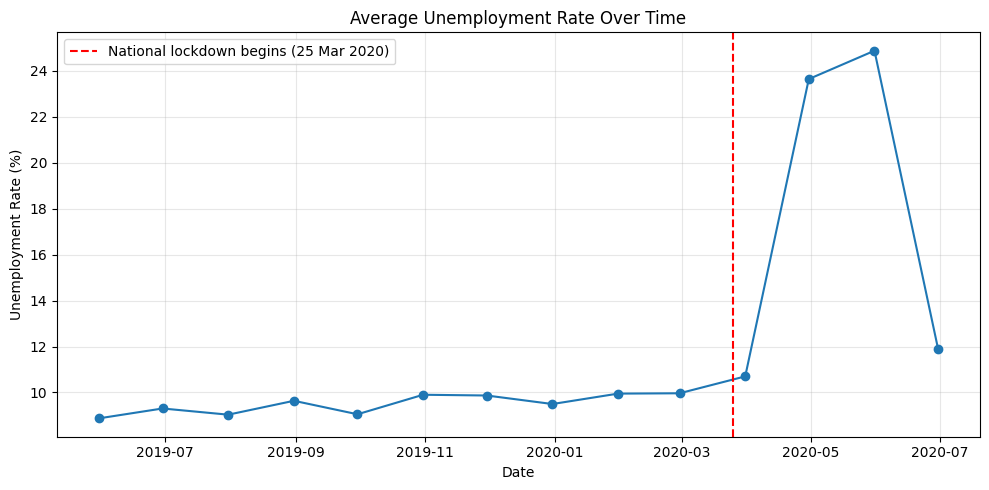

In [18]:
monthly = df.groupby('Date')['Estimated Unemployment Rate (%)'].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker='o')
plt.axvline(pd.Timestamp('2020-03-25'), color='red', linestyle='--',
            label='National lockdown begins (25 Mar 2020)')
plt.title('Average Unemployment Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

* Unemployment was relatively stable around 9–10% before early 2020.
* It increased sharply beginning around April 2020.
* May 2020 had the highest average monthly unemployment rate (~24.88%).
* June 2020 saw a substantial decline.

### When was unemployment highest and lowest?

In [19]:
df.loc[df['Estimated Unemployment Rate (%)'].idxmax()]

,627
Region,Puducherry
Date,2020-04-30 00:00:00
Frequency,Monthly
Estimated Unemployment Rate (%),76.74
Estimated Employed,68122.0
Estimated Labour Participation Rate (%),35.54
Area,Urban
Period,Lockdown (Apr - May 20)


#### Puducherry recorded the highest individual observation.

In [20]:
df.loc[df['Estimated Unemployment Rate (%)'].idxmin()]

,25
Region,Assam
Date,2020-06-30 00:00:00
Frequency,Monthly
Estimated Unemployment Rate (%),0.0
Estimated Employed,7544937.0
Estimated Labour Participation Rate (%),34.38
Area,Rural
Period,Post-lockdown (Jun 20)


#### Assam recorded the lowest individual observation.

### Which region had the highest unemployment?

In [21]:
df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False).head(5)

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357


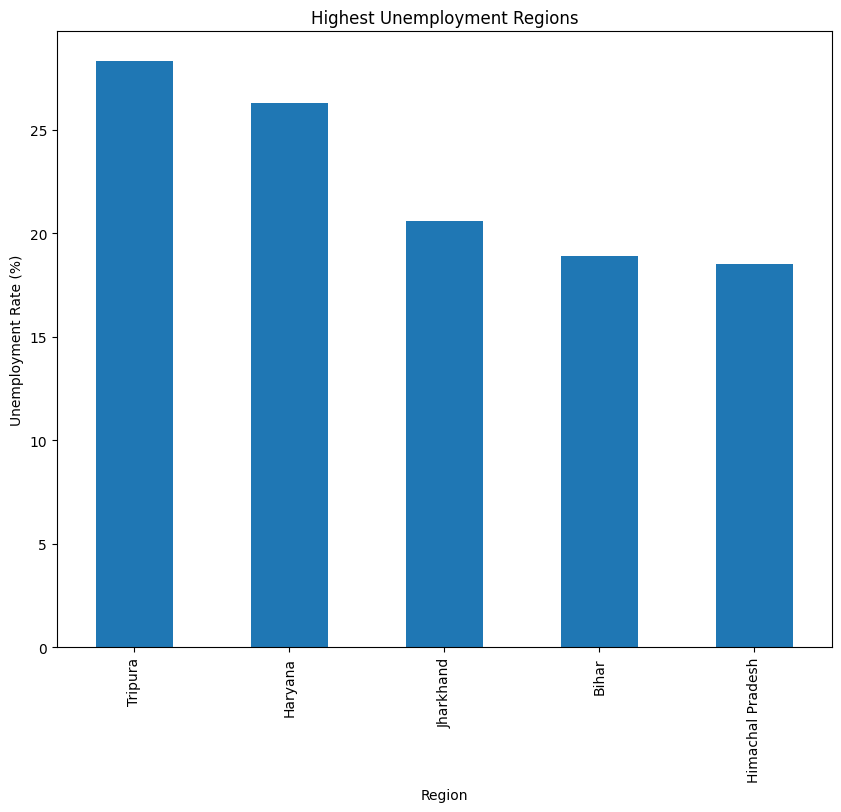

In [22]:
df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False).head(5).plot(
    kind='bar',
    figsize=(10, 8),
    title='Highest Unemployment Regions',
    xlabel='Region',
    ylabel='Unemployment Rate (%)'
)
plt.show()

#### Some regions had considerably higher average unemployment than others.

### Regional comparison

Area
Urban    13.166614
Rural    10.324791
Name: Estimated Unemployment Rate (%), dtype: float64


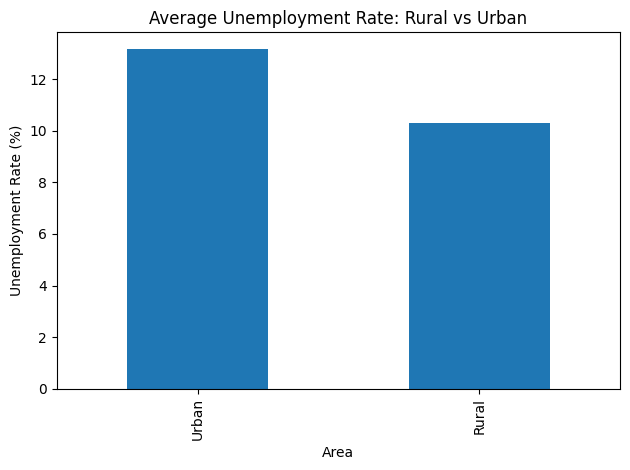

In [23]:
# Compare unemployment by area
area_avg = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

print(area_avg)

area_avg.plot(
    kind='bar',
    title='Average Unemployment Rate: Rural vs Urban',
    xlabel='Area',
    ylabel='Unemployment Rate (%)'
)

plt.tight_layout()
plt.show()

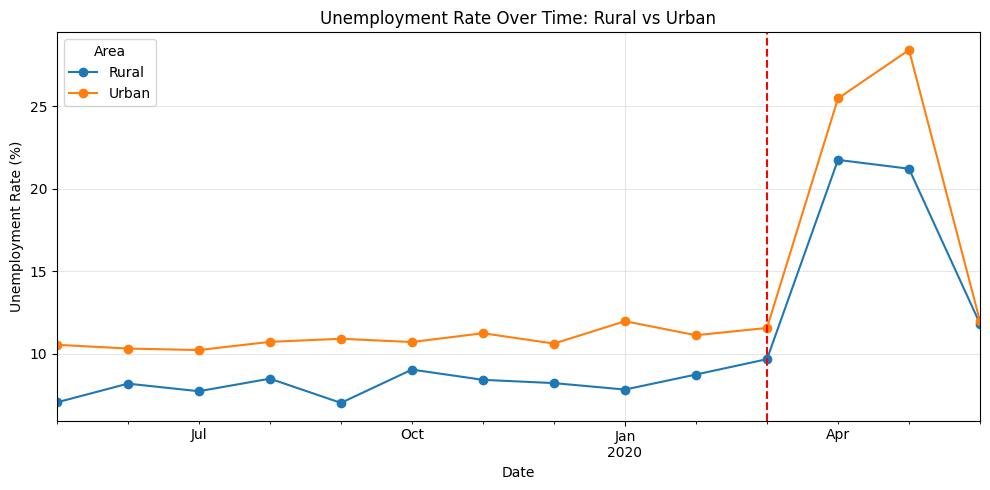

In [24]:
# Did urban and rural areas react differently over time?
area_time = df.groupby(['Date', 'Area'])['Estimated Unemployment Rate (%)'].mean().unstack()

area_time.plot(figsize=(10, 5), marker='o',
               title='Unemployment Rate Over Time: Rural vs Urban')
plt.axvline(pd.Timestamp('2020-03-25'), color='red', linestyle='--')
plt.ylabel('Unemployment Rate (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Urban areas had higher unemployment than rural areas throughout the period and were hit harder by the lockdown. Urban unemployment rose from about 11.5% in March to roughly 28% in May 2020, while rural unemployment peaked at about 22% in April. By June 2020 the two had converged at around 12%.

In [25]:
area_period = df.pivot_table(index='Area', columns='Period',
                             values='Estimated Unemployment Rate (%)',
                             aggfunc='mean', observed=True)
area_period['Increase (pp)'] = area_period[LOCK] - area_period[PRE]
area_period.round(2)

Period,Pre-Covid (May 19 - Mar 20),Lockdown (Apr - May 20),Post-lockdown (Jun 20),Increase (pp)
Area,,,,
Rural,8.23,21.48,11.83,13.25
Urban,10.91,26.93,11.98,16.02


## Impact of Covid-19 on Unemployment

#### Did unemployment increase noticeably around 2020?

In [26]:
df.groupby(df['Date'].dt.year)['Estimated Unemployment Rate (%)'].mean()

,Estimated Unemployment Rate (%)
Date,
2019,9.399047
2020,15.101581


Period
Pre-Covid (May 19 - Mar 20)     9.61
Lockdown (Apr - May 20)        24.26
Post-lockdown (Jun 20)         11.90
Name: Estimated Unemployment Rate (%), dtype: float64


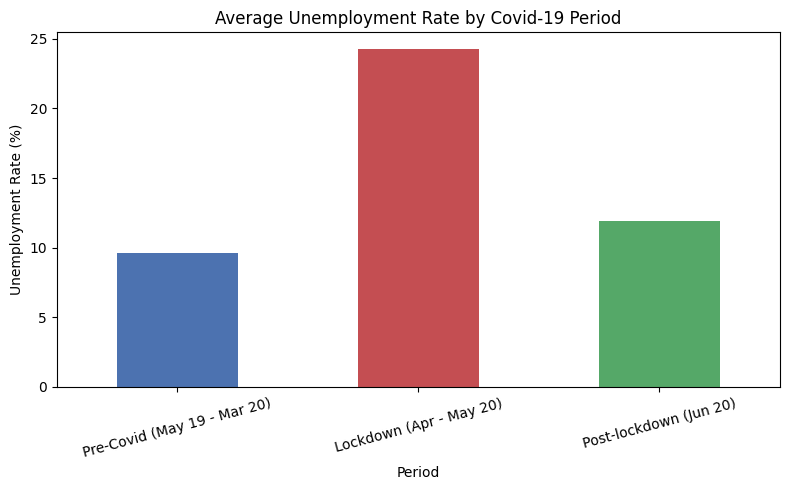

In [27]:
# Average unemployment by period
period_avg = df.groupby('Period', observed=True)['Estimated Unemployment Rate (%)'].mean()
print(period_avg.round(2))

period_avg.plot(kind='bar', figsize=(8, 5), color=['#4c72b0', '#c44e52', '#55a868'],
                title='Average Unemployment Rate by Covid-19 Period')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### Average unemployment rose from about 9.6% before the lockdown to about 24.3% during April-May 2020, roughly two and a half times higher. It fell back to about 11.9% in June 2020, still above the pre-Covid level.

Region
Puducherry        73.84
Jharkhand         43.16
Tamil Nadu        37.69
Bihar             33.26
Karnataka         21.20
Madhya Pradesh    17.27
Haryana           17.12
Andhra Pradesh    16.78
Telangana         16.63
Kerala            14.28
Name: Increase (pp), dtype: float64


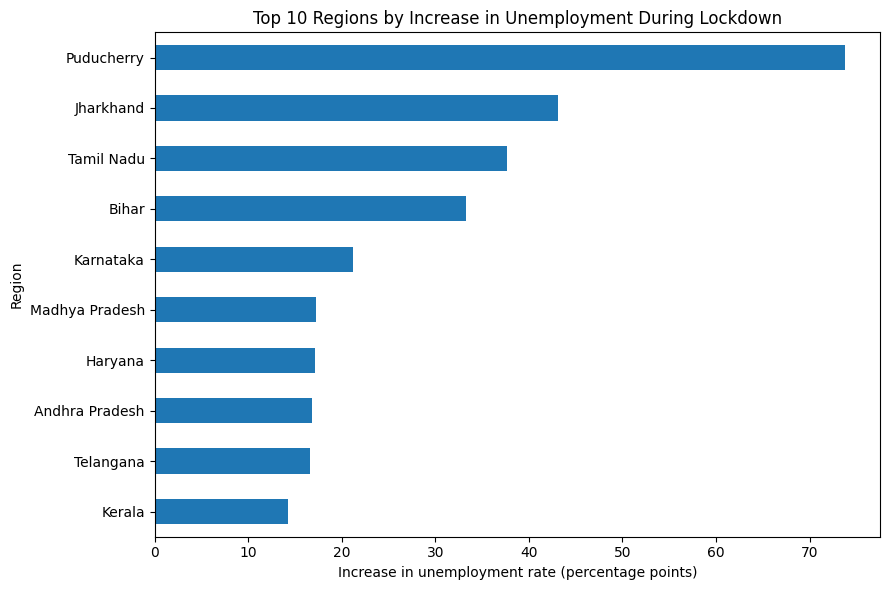

In [28]:
# Which regions were hit hardest? (lockdown average minus pre-Covid average)
region_period = df.pivot_table(index='Region', columns='Period',
                               values='Estimated Unemployment Rate (%)', aggfunc='mean', observed=True)
region_period['Increase (pp)'] = region_period[LOCK] - region_period[PRE]

hit_hardest = region_period['Increase (pp)'].sort_values(ascending=False)
print(hit_hardest.head(10).round(2))

hit_hardest.head(10).sort_values().plot(
    kind='barh', figsize=(9, 6),
    title='Top 10 Regions by Increase in Unemployment During Lockdown')
plt.xlabel('Increase in unemployment rate (percentage points)')
plt.tight_layout()
plt.show()

#### Puducherry (+73.8 percentage points), Jharkhand (+43.2), Tamil Nadu (+37.7), Bihar (+33.3) and Karnataka (+21.2) saw the largest increases during lockdown. Puducherry's rise is extreme and should be read with caution. Tripura has the highest overall average but does not appear in the top 10 increases, which suggests its unemployment was already high before Covid-19 rather than caused by it.

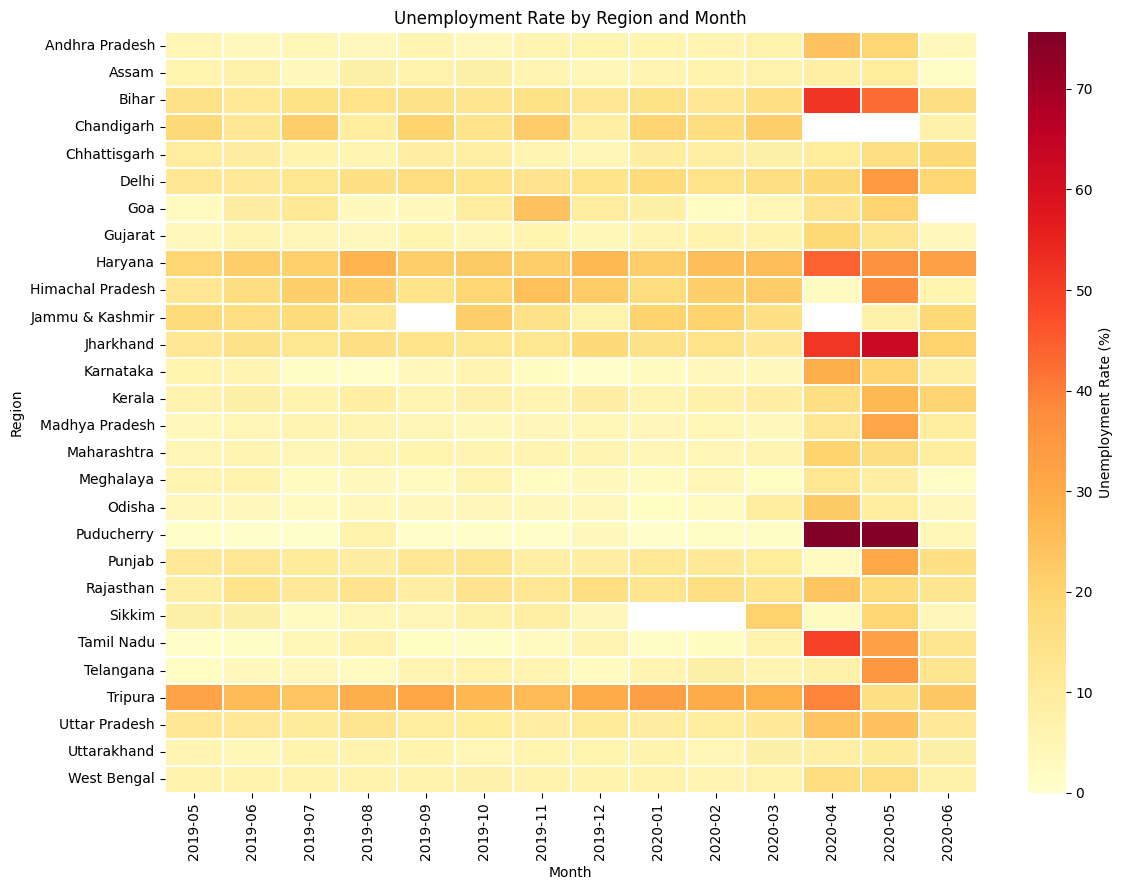

In [29]:
# Region x month heatmap
heat = df.pivot_table(index='Region',
                      columns=df['Date'].dt.to_period('M'),
                      values='Estimated Unemployment Rate (%)', aggfunc='mean')

plt.figure(figsize=(12, 9))
sns.heatmap(heat, cmap='YlOrRd', linewidths=0.3,
            cbar_kws={'label': 'Unemployment Rate (%)'})
plt.title('Unemployment Rate by Region and Month')
plt.xlabel('Month')
plt.tight_layout()
plt.show()

#### Unemployment was low and fairly stable in most regions until March 2020. The darkest cells appear in April-May 2020, especially for Puducherry, Jharkhand, Bihar and Tamil Nadu. Tripura and Haryana show consistently high rates throughout the year. Some region-month cells are blank (for example Chandigarh in Apr-May 2020 and Sikkim in Jan-Feb 2020), which means those observations are missing from the dataset and may affect the averages.

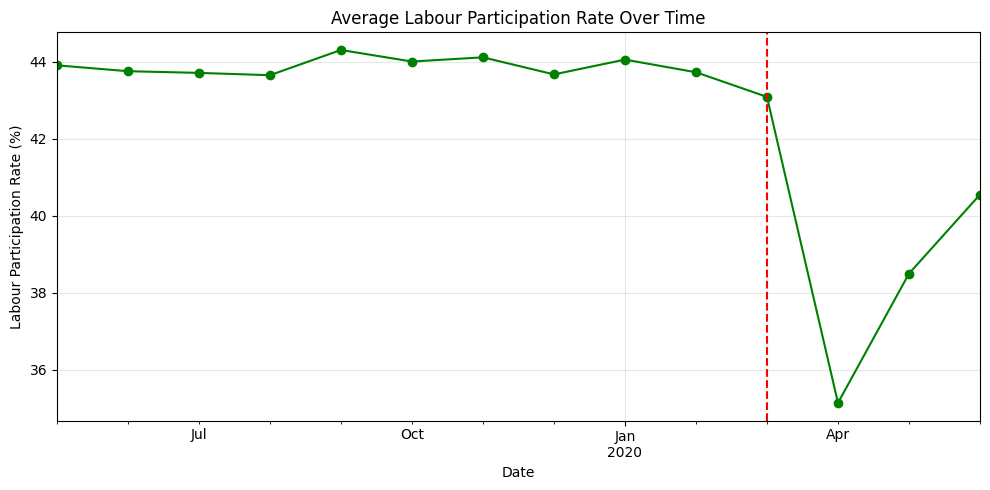

In [30]:
# Labour participation over time
df.groupby('Date')['Estimated Labour Participation Rate (%)'].mean().plot(
    figsize=(10, 5), marker='o', color='green',
    title='Average Labour Participation Rate Over Time')
plt.axvline(pd.Timestamp('2020-03-25'), color='red', linestyle='--')
plt.ylabel('Labour Participation Rate (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### The average labour participation rate held steady at roughly 43-44% before the lockdown, then dropped to about 35% in April 2020. It recovered to about 40.5% by June 2020 but remained below its pre-Covid level, so the labour market had not fully recovered in the data.

## How quickly did it recover?

In [31]:
# Calculate average unemployment by month
monthly_rate = df.groupby(
    df['Date'].dt.to_period('M')
)['Estimated Unemployment Rate (%)'].mean()

# Calculate month-to-month change in percentage points
monthly_change = monthly_rate.diff()

monthly_change

,Estimated Unemployment Rate (%)
Date,
2019-05,NaN
2019-06,0.429074
2019-07,-0.269444
2019-08,0.604036
2019-09,-0.586194
2019-10,0.849178
2019-11,-0.032545
2019-12,-0.371005
2020-01,0.453396


In [32]:
# Compare May and June 2020 average unemployment
may_rate = monthly_rate.loc[pd.Period('2020-05', freq='M')]
june_rate = monthly_rate.loc[pd.Period('2020-06', freq='M')]

# Absolute change in percentage points
print("Change:", round(june_rate - may_rate, 2), "percentage points")

# Relative percentage change
percentage_change = ((june_rate - may_rate) / may_rate) * 100

print("Percentage change:", round(percentage_change, 2), "%")

Change: -12.97 percentage points
Percentage change: -52.15 %


#### Unemployment showed an initial recovery in June 2020, falling substantially from its May peak. However, because the dataset ends in June 2020, the longer term recovery cannot be assessed.

## Seasonal Trends

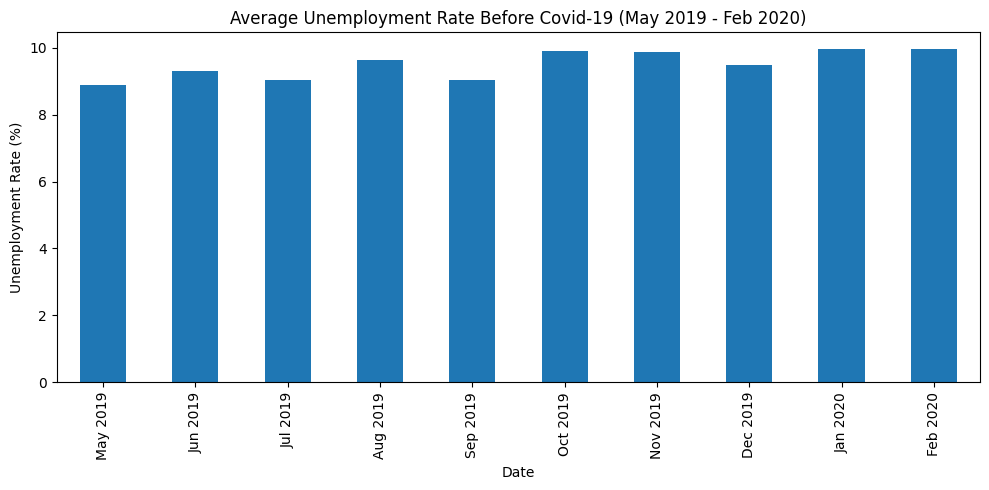

In [33]:
# Pre-Covid months only, so the lockdown spike doesn't distort the pattern
pre_covid = df[df['Date'] <= '2020-02-29'].groupby('Date')['Estimated Unemployment Rate (%)'].mean()
pre_covid.index = pre_covid.index.strftime('%b %Y')

pre_covid.plot(kind='bar', figsize=(10, 5),
               title='Average Unemployment Rate Before Covid-19 (May 2019 - Feb 2020)')
plt.ylabel('Unemployment Rate (%)')
plt.tight_layout()
plt.show()

#### Before Covid-19, the average rate stayed in a narrow band of roughly 9-10%, with no strong pattern. Because each calendar month is observed only once (May 2019 to Jun 2020), no seasonal pattern can be reliably identified. The higher values for April-June are caused by the Covid-19 lockdown and should not be interpreted as seasonality.

## Policy Recommendations

1. **Target the hardest hit regions.** Puducherry, Jharkhand, Tamil Nadu and Bihar saw the largest lockdown increases in unemployment. Emergency support should be directed to regions with the sharpest rises rather than spread evenly.
2. **Separate responses for urban and rural areas.** Urban unemployment peaked higher (about 28% in May 2020) than rural (about 22% in April 2020), suggesting urban job support and wage protection schemes are needed alongside rural employment programmes.
3. **Address long-standing high unemployment separately.** Tripura and Haryana had high unemployment before Covid-19, so they likely need structural job creation policies rather than only crisis relief.
4. **Prepare rapid-response measures.** Average unemployment more than doubled within a single month (March to April 2020), so governments need early warning labour data and relief schemes that can be activated quickly.
5. **Monitor recovery, not just unemployment.** Labour participation was still below its pre-Covid level in June 2020, so unemployment figures alone may understate the damage.

These are recommendations based on observed patterns, not proven solutions established by this analysis.

## Conclusion and Limitations

Average unemployment was stable at about 9.6% before the lockdown, rose to about 24.3% in April-May 2020, and fell to about 11.9% in June 2020. Urban areas and a small group of regions (notably Puducherry, Jharkhand, Tamil Nadu and Bihar) were hit hardest, and labour participation fell from about 44% to 35% before partly recovering.

**Limitations**

- The dataset covers only May 2019 to June 2020, so it cannot show long-term recovery or reliably identify recurring seasonal patterns.
- Some region-month observations are missing (for example Chandigarh in April-May 2020), which may affect the averages.
- Averages are simple means across regions and areas, not weighted by population or labour force size, so small regions count as much as large ones.
- The changes are associated with the early Covid-19 period, but this analysis alone cannot prove causation.

| Column                                      | Description                                                                                                                                 |
| ------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------- |
| **Region**                                  | The state or geographical region represented by the data.                                                                                   |
| **Date**                                    | The date or period when the unemployment data was recorded.                                                                                 |
| **Frequency**                               | The frequency at which the data was collected, such as monthly.                                                                             |
| **Estimated Unemployment Rate (%)**         | The estimated percentage of the labour force that is unemployed.                                                                            |
| **Estimated Employed**                      | The estimated number of people who are employed during the recorded period.                                                                 |
| **Estimated Labour Participation Rate (%)** | The estimated percentage of the working-age population participating in the labour force, either by working or actively seeking employment. |
| **Area**                                    | Indicates whether the observation represents an **urban** or **rural** area.                                                                |